In [32]:
import pandas as pd
import matplotlib.pyplot as plt

In [33]:
df = pd.read_csv('../data/raw/eurostat_sts_inppd_m_de_2010_2025.csv')

In [34]:
df.head()

,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,indic_bt,Business trend indicator,nace_r2,Statistical classification of economic activities in the European Community (NACE Rev. 2),s_adj,...,geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:STS_INPPD_M(1.0),"Producer prices in industry, domestic market -...",M,Monthly,PRC_PRR_DOM,Domestic producer prices,C,Manufacturing,NSA,...,DE,Germany,2010-01,NaN,85.2,NaN,NaN,NaN,NaN,NaN
1,dataflow,ESTAT:STS_INPPD_M(1.0),"Producer prices in industry, domestic market -...",M,Monthly,PRC_PRR_DOM,Domestic producer prices,C,Manufacturing,NSA,...,DE,Germany,2010-02,NaN,85.3,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:STS_INPPD_M(1.0),"Producer prices in industry, domestic market -...",M,Monthly,PRC_PRR_DOM,Domestic producer prices,C,Manufacturing,NSA,...,DE,Germany,2010-03,NaN,85.7,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:STS_INPPD_M(1.0),"Producer prices in industry, domestic market -...",M,Monthly,PRC_PRR_DOM,Domestic producer prices,C,Manufacturing,NSA,...,DE,Germany,2010-04,NaN,86.4,NaN,NaN,NaN,NaN,NaN
4,dataflow,ESTAT:STS_INPPD_M(1.0),"Producer prices in industry, domestic market -...",M,Monthly,PRC_PRR_DOM,Domestic producer prices,C,Manufacturing,NSA,...,DE,Germany,2010-05,NaN,86.7,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(df['OBS_FLAG'].unique())
print(df['Observation status (Flag) V2 structure'].unique())
print(df['Time'].unique())
print(df['Observation value'].unique())
print(df['CONF_STATUS'].unique())
print(df['Confidentiality status (flag)'].unique())
print(df['STRUCTURE'].nunique())
print(df['STRUCTURE_ID'].nunique())
print(df['STRUCTURE_NAME'].nunique())

[nan]
[nan]
[nan]
[nan]
[nan]
[nan]
1
1
1


In [36]:
for col in ["geo", "freq", "indic_bt", "s_adj", "unit", "nace_r2"]:
    print(col, df[col].unique())

print("Размер:", df.shape)
print("Период:", df["TIME_PERIOD"].min(), "—", df["TIME_PERIOD"].max())

coverage = df.groupby("nace_r2").agg(
    rows=("TIME_PERIOD", "size"),
    months=("TIME_PERIOD", "nunique"),
    available_values=("OBS_VALUE", "count"),
)

coverage["missing_values"] = (
    coverage["rows"] - coverage["available_values"]
)

display(coverage)

print(
    "Дубликаты:",
    df.duplicated(
        subset=["geo", "nace_r2", "TIME_PERIOD"]
    ).sum(),
)

geo <StringArray>
['DE']
Length: 1, dtype: str
freq <StringArray>
['M']
Length: 1, dtype: str
indic_bt <StringArray>
['PRC_PRR_DOM']
Length: 1, dtype: str
s_adj <StringArray>
['NSA']
Length: 1, dtype: str
unit <StringArray>
['I21']
Length: 1, dtype: str
nace_r2 <StringArray>
[      'C',     'C10',     'C11',     'C12',     'C13',     'C14',     'C15',
     'C16',     'C17',     'C18',     'C19',     'C20',     'C21',     'C22',
     'C23',     'C24',     'C25',     'C26',     'C27',     'C28',     'C29',
     'C30',     'C31',     'C32',     'C33',    'D351',    'D352', 'MIG_NRG']
Length: 28, dtype: str
Размер: (5376, 23)
Период: 2010-01 — 2025-12


,rows,months,available_values,missing_values
nace_r2,,,,
C,192,192,192,0
C10,192,192,192,0
C11,192,192,192,0
C12,192,192,192,0
C13,192,192,192,0
C14,192,192,192,0
C15,192,192,192,0
C16,192,192,192,0
C17,192,192,192,0


Дубликаты: 0


In [37]:
keep_cols = [
    "geo",
    "nace_r2",
    "Statistical classification of economic activities in the European Community (NACE Rev. 2)",
    "TIME_PERIOD",
    "OBS_VALUE",
    "unit",
    "s_adj",
]

prices = df[keep_cols].copy()

prices = prices.rename(columns={
    "nace_r2": "price_sector",
    "Statistical classification of economic activities in the European Community (NACE Rev. 2)": "price_sector_name",
    "TIME_PERIOD": "date",
    "OBS_VALUE": "price_index",
})

prices["date"] = pd.to_datetime(prices["date"], format="%Y-%m")

prices = prices.sort_values(
    ["geo", "price_sector", "date"]
).reset_index(drop=True)

prices.head()

,geo,price_sector,price_sector_name,date,price_index,unit,s_adj
0,DE,C,Manufacturing,2010-01-01,85.2,I21,NSA
1,DE,C,Manufacturing,2010-02-01,85.3,I21,NSA
2,DE,C,Manufacturing,2010-03-01,85.7,I21,NSA
3,DE,C,Manufacturing,2010-04-01,86.4,I21,NSA
4,DE,C,Manufacturing,2010-05-01,86.7,I21,NSA


In [38]:
prices['prices_mom_pct'] = (
    prices
    .groupby(['geo', 'price_sector'])['price_index']
    .pct_change(fill_method=None)
    .mul(100)
)


prices['prices_yoy_pct'] = (
    prices
    .groupby(['geo', 'price_sector'])['price_index']
    .pct_change(periods=12, fill_method=None)
    .mul(100)
)

prices.head()

,geo,price_sector,price_sector_name,date,price_index,unit,s_adj,prices_mom_pct,prices_yoy_pct
0,DE,C,Manufacturing,2010-01-01,85.2,I21,NSA,NaN,NaN
1,DE,C,Manufacturing,2010-02-01,85.3,I21,NSA,0.117371,NaN
2,DE,C,Manufacturing,2010-03-01,85.7,I21,NSA,0.468933,NaN
3,DE,C,Manufacturing,2010-04-01,86.4,I21,NSA,0.816803,NaN
4,DE,C,Manufacturing,2010-05-01,86.7,I21,NSA,0.347222,NaN


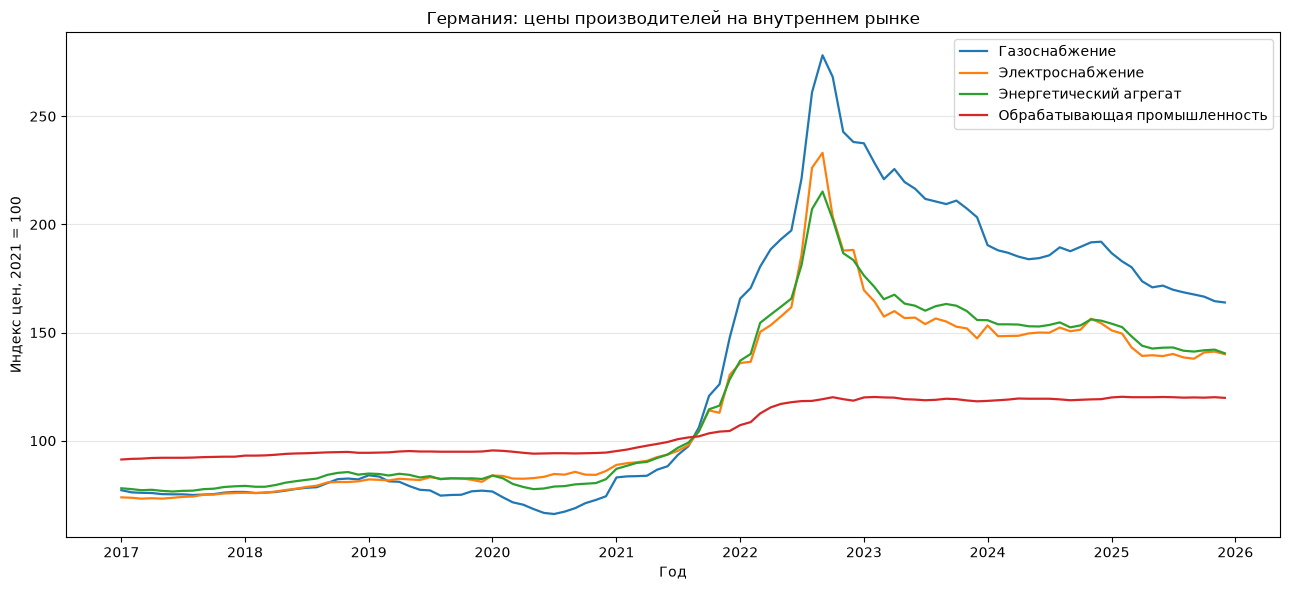

In [39]:
series_names = {
    "D352": "Газоснабжение",
    "D351": "Электроснабжение",
    "MIG_NRG": "Энергетический агрегат",
    "C": "Обрабатывающая промышленность",
}

fig, ax = plt.subplots(figsize=(13, 6))

for sector, label in series_names.items():
    subset = prices.loc[
        prices["price_sector"].eq(sector)
        & prices["date"].ge("2017-01-01")
    ].sort_values("date")

    ax.plot(
        subset["date"],
        subset["price_index"],
        label=label,
        linewidth=1.6,
    )

ax.set_title("Германия: цены производителей на внутреннем рынке")
ax.set_xlabel("Год")
ax.set_ylabel("Индекс цен, 2021 = 100")
ax.grid(axis="y", alpha=0.3)
ax.legend()

fig.tight_layout()
fig.savefig(
    "../figure/energy_price_indices.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()

In [40]:
prices.to_csv(
    "../data/processed/prices_monthly.csv",
    index=False,
    date_format="%Y-%m-%d",
)